# Dark view

Opens the dark maps written by `calib_stack.ipynb` (mean, std_excess in ADU/s, and nclip, for one exposure time)
and shows each one in its own cell: image, histogram and its numbers, with the limits set by hand in the cell.

In [30]:
import os
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

TEL = 'zb08'
N_START = 1300
N_STOP = 1310

IN_DIR = os.path.expanduser(f'~/data/ocm_dark/{TEL}')

maps = {}
for name in ['mean', 'std_excess', 'nclip']:
    maps[name] = fits.getdata(f'{IN_DIR}/{TEL}_{N_START}_{N_STOP}_{name}.fits')
    print(name, maps[name].shape)

# exposure time of the darks, from the header of the stack
EXPTIME = fits.getheader(f'{IN_DIR}/{TEL}_{N_START}_{N_STOP}_mean.fits')['EXPTIME']
print('EXPTIME', EXPTIME, 's')

UNIT = 'ADU/s'

FileNotFoundError: [Errno 2] No such file or directory: '/home/mgorski/data/ocm_dark/zb08/zb08_1300_1310_mean.fits'

In [ ]:
# what the maps were made from, from the header of the stack
h = fits.getheader(f'{IN_DIR}/{TEL}_{N_START}_{N_STOP}_mean.fits')
print(f"{h['NDARK']} darks of {h['EXPTIME']:.0f} s, nights {h['NIGHT-BG']}-{h['NIGHT-EN']}, bias {h['BIAS']}")

## mean

The dark current of every pixel. `hi = 0.1` ADU/s (20 x the typical pixel) marks the hot pixels; limits from the
median and sigma would also catch the top of the frame, where the dark current has a gradient.

mean:  average 0.00583657   median 0.00498835   sigma 0.003528 ADU/s   205 above 0.5 (red)   0 below -0.01265 (blue)


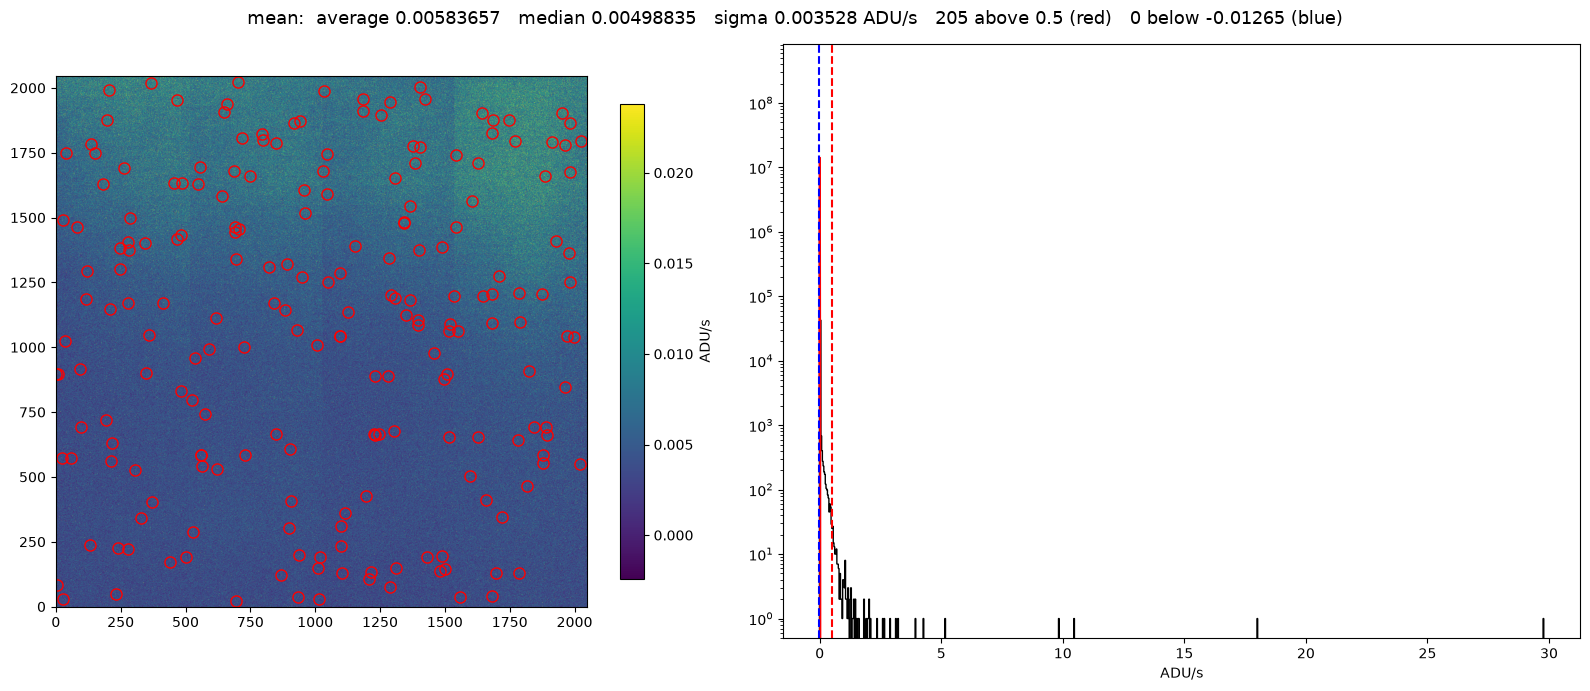

In [26]:
m = maps['mean']
mu = np.median(m)
sigma = 1.4826 * np.median(np.abs(m - mu))

# set by hand: pixels below lo are marked blue, above hi red; vmin, vmax = colour scale; bins = number of histogram bins
lo = mu - 5 * sigma
hi = 0.5


vmin = np.percentile(m, 0.5)
vmax = np.percentile(m, 99.5)
bins = 1000

y_hi, x_hi = np.where(m > hi)
y_lo, x_lo = np.where(m < lo)

text = f'mean:  average {np.mean(m):.6g}   median {mu:.6g}   sigma {sigma:.4g} ADU/s   {len(x_hi)} above {hi:.4g} (red)   {len(x_lo)} below {lo:.4g} (blue)'
print(text)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={'width_ratios': [1, 1.2]})
fig.suptitle(text, fontsize=13)

# image with the marked pixels: circles, or small dots if there are more than MAX_MARK
im = ax1.imshow(m, origin='lower', vmin=vmin, vmax=vmax, cmap='viridis')
if len(x_hi) + len(x_lo) <= MAX_MARK:
    ax1.plot(x_hi, y_hi, 'o', mfc='none', mec='r', ms=8)
    ax1.plot(x_lo, y_lo, 'o', mfc='none', mec='b', ms=8)
else:
    ax1.plot(x_hi, y_hi, '.', color='r', ms=2)
    ax1.plot(x_lo, y_lo, '.', color='b', ms=2)
fig.colorbar(im, ax=ax1, shrink=0.8, label='ADU/s')

# histogram with the Gaussian (median, sigma) and the two limits
v = m.ravel()
counts, edges, _ = ax2.hist(v, bins=bins, histtype='step', color='k')
width = edges[1] - edges[0]  # width of the bins, to scale the Gaussian to the counts
if sigma > 0:
    x = np.linspace(v.min(), v.max(), 2000)
    gauss = len(v) * width / (sigma * np.sqrt(2 * np.pi)) * np.exp(-0.5 * ((x - mu) / sigma) ** 2)
    ax2.plot(x, gauss, 'r')
ax2.axvline(hi, color='r', ls='--')
ax2.axvline(lo, color='b', ls='--')
ax2.set_yscale('log')
ax2.set_ylim(0.5, None)
ax2.set_xlabel('ADU/s')

plt.tight_layout()
plt.show()

## std_excess

The noise of the dark signal without the read noise. 0 for about half of the pixels; the tail are the pixels that
scatter clearly more than the read noise.

std_excess:  average 0.00254815   median 0.00135576   sigma 0.00201 ADU/s   201 above 0.02146 (red)   0 below -0.01874 (blue)


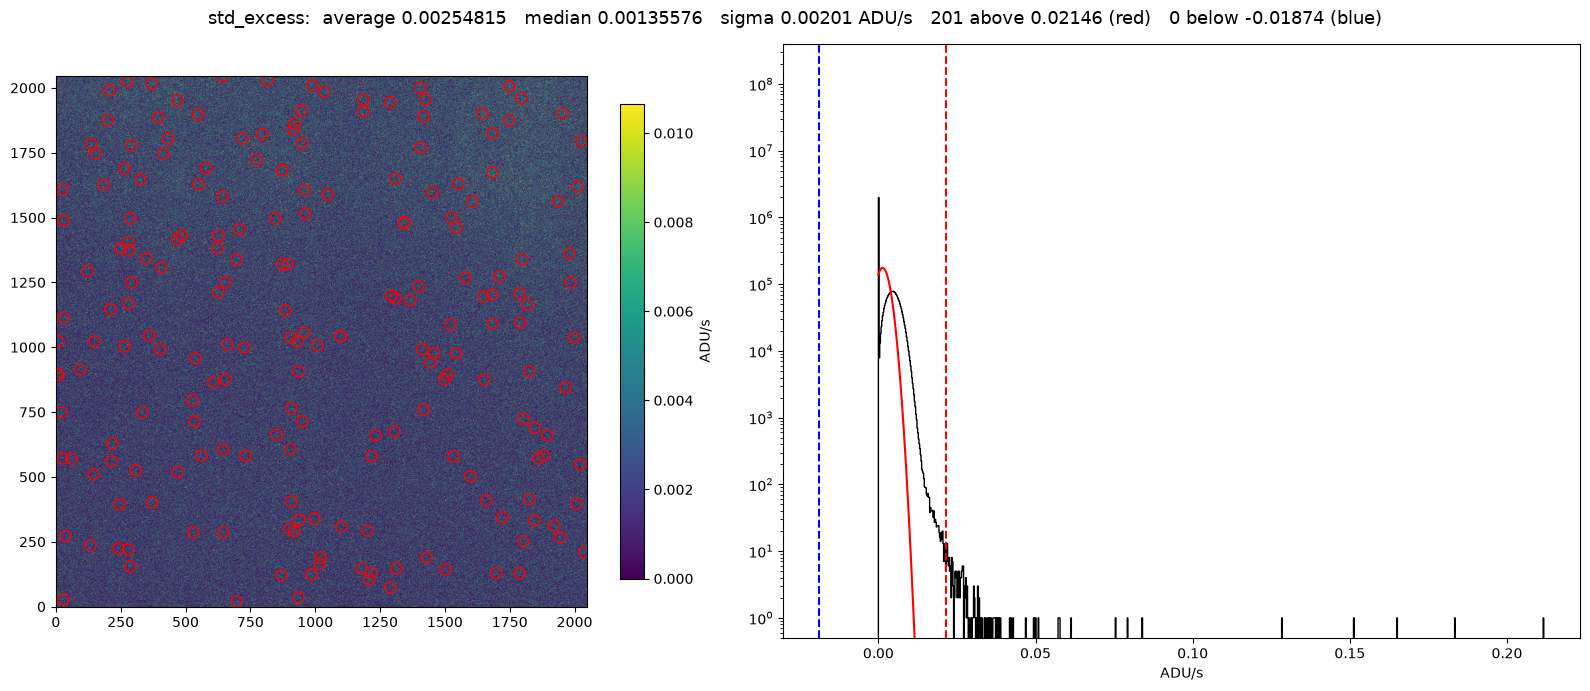

In [27]:
m = maps['std_excess']
mu = np.median(m)
sigma = 1.4826 * np.median(np.abs(m - mu))

# set by hand: pixels below lo are marked blue, above hi red; vmin, vmax = colour scale; bins = number of histogram bins
lo = mu - 10 * sigma
hi = mu + 10 * sigma
vmin = np.percentile(m, 0.5)
vmax = np.percentile(m, 99.5)
bins = 1000

y_hi, x_hi = np.where(m > hi)
y_lo, x_lo = np.where(m < lo)

text = f'std_excess:  average {np.mean(m):.6g}   median {mu:.6g}   sigma {sigma:.4g} ADU/s   {len(x_hi)} above {hi:.4g} (red)   {len(x_lo)} below {lo:.4g} (blue)'
print(text)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={'width_ratios': [1, 1.2]})
fig.suptitle(text, fontsize=13)

# image with the marked pixels: circles, or small dots if there are more than MAX_MARK
im = ax1.imshow(m, origin='lower', vmin=vmin, vmax=vmax, cmap='viridis')
if len(x_hi) + len(x_lo) <= MAX_MARK:
    ax1.plot(x_hi, y_hi, 'o', mfc='none', mec='r', ms=8)
    ax1.plot(x_lo, y_lo, 'o', mfc='none', mec='b', ms=8)
else:
    ax1.plot(x_hi, y_hi, '.', color='r', ms=2)
    ax1.plot(x_lo, y_lo, '.', color='b', ms=2)
fig.colorbar(im, ax=ax1, shrink=0.8, label='ADU/s')

# histogram with the Gaussian (median, sigma) and the two limits
v = m.ravel()
counts, edges, _ = ax2.hist(v, bins=bins, histtype='step', color='k')
width = edges[1] - edges[0]  # width of the bins, to scale the Gaussian to the counts
if sigma > 0:
    x = np.linspace(v.min(), v.max(), 2000)
    gauss = len(v) * width / (sigma * np.sqrt(2 * np.pi)) * np.exp(-0.5 * ((x - mu) / sigma) ** 2)
    ax2.plot(x, gauss, 'r')
ax2.axvline(hi, color='r', ls='--')
ax2.axvline(lo, color='b', ls='--')
ax2.set_yscale('log')
ax2.set_ylim(0.5, None)
ax2.set_xlabel('ADU/s')

plt.tight_layout()
plt.show()

## nclip

How many values of every pixel were rejected by the clipping. `hi = 0.5` marks every pixel with at least one.

nclip:  average 0.00591207   median 0   sigma 0 values   63 above 1.5 (red)   0 below -0.5 (blue)


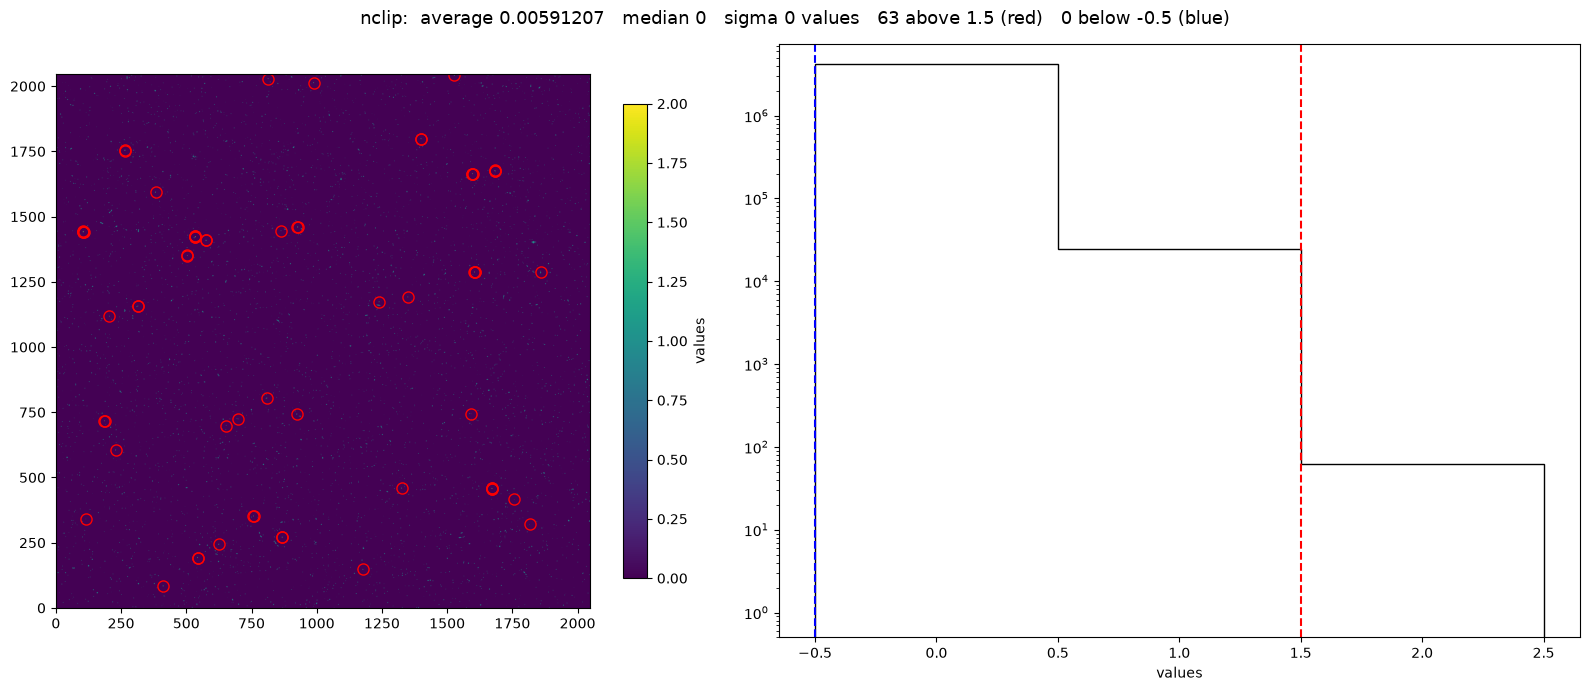

In [28]:
m = maps['nclip']
mu = np.median(m)
sigma = 1.4826 * np.median(np.abs(m - mu))

# set by hand: pixels below lo are marked blue, above hi red; vmin, vmax = colour scale; bins = number of histogram bins
lo = -0.5
hi = 1.5

vmin = 0
vmax = 2
bins = np.arange(-0.5, m.max() + 1)  # one bin per value

y_hi, x_hi = np.where(m > hi)
y_lo, x_lo = np.where(m < lo)

text = f'nclip:  average {np.mean(m):.6g}   median {mu:.6g}   sigma {sigma:.4g} values   {len(x_hi)} above {hi:.4g} (red)   {len(x_lo)} below {lo:.4g} (blue)'
print(text)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={'width_ratios': [1, 1.2]})
fig.suptitle(text, fontsize=13)

# image with the marked pixels: circles, or small dots if there are more than MAX_MARK
im = ax1.imshow(m, origin='lower', vmin=vmin, vmax=vmax, cmap='viridis')
if len(x_hi) + len(x_lo) <= MAX_MARK:
    ax1.plot(x_hi, y_hi, 'o', mfc='none', mec='r', ms=8)
    ax1.plot(x_lo, y_lo, 'o', mfc='none', mec='b', ms=8)
else:
    ax1.plot(x_hi, y_hi, '.', color='r', ms=2)
    ax1.plot(x_lo, y_lo, '.', color='b', ms=2)
fig.colorbar(im, ax=ax1, shrink=0.8, label='values')

# histogram with the Gaussian (median, sigma) and the two limits
v = m.ravel()
counts, edges, _ = ax2.hist(v, bins=bins, histtype='step', color='k')
width = edges[1] - edges[0]  # width of the bins, to scale the Gaussian to the counts
if sigma > 0:
    x = np.linspace(v.min(), v.max(), 2000)
    gauss = len(v) * width / (sigma * np.sqrt(2 * np.pi)) * np.exp(-0.5 * ((x - mu) / sigma) ** 2)
    ax2.plot(x, gauss, 'r')
ax2.axvline(hi, color='r', ls='--')
ax2.axvline(lo, color='b', ls='--')
ax2.set_yscale('log')
ax2.set_ylim(0.5, None)
ax2.set_xlabel('values')

plt.tight_layout()
plt.show()